# A latent with exactly Gaussian marginals and jump-like regime dynamics

LeJEPA's SIGReg pushes the marginal of the embedding towards $\mathcal N(0, I)$. Can such a representation still reveal metastable regime switching? Yes, through its **temporal** non-Gaussianity: a Gaussian marginal does not make $(z_t, z_{t+\tau})$ jointly Gaussian. A jointly Gaussian stationary process has Gaussian increments, so its increment excess kurtosis is zero. A switching process can keep $z_t \sim \mathcal N(0, I)$ exactly and still have heavy-tailed increments.

This notebook builds two such latents (`gauss_switch` source in `cpbench/data/structured.py`), checks that the marginal is exactly $\mathcal N(0,I)$, derives the **increment kurtosis spectrum** $\kappa_\tau(u)$ in closed form, shows that it encodes the regime dwell time, and runs every detector on the latent directly, against a jointly Gaussian twin with the same second-order statistics.

## The two constructions

Let $S_t$ be a sticky K-state Markov chain with uniform stationary law and geometric dwell (switch hazard $h = 1/\text{dwell}$ per step), and $e_t$ independent unit-variance AR(1) coordinates with $\rho = e^{-1/\ell}$ ($\ell = 0$: white).

**Fresh levels** (`coding="fresh"`): $z_t = \sqrt{c}\, m_{j(t)} + \sqrt{1-c}\, e_t$, with a new $m_j \sim \mathcal N(0, I)$ for each regime segment $j$. A sum of independent Gaussians, so $z_t \sim \mathcal N(0, I)$ exactly; every direction jumps at every switch, but the regime *label* is not encoded (change points only).

**Quantile bands** (`coding="bands"`): along one unit direction $u$, $z_t\cdot u = \Phi^{-1}\big((\pi(S_t) + \Phi(e_{t,1}))/K\big)$, the other $d-1$ directions are $e$. Since $S_t$ is uniform and $\Phi(e_{t,1})$ is uniform, the argument is uniform on $(0,1)$, so $z_t\cdot u \sim \mathcal N(0,1)$ exactly, independent of the other directions: $z_t \sim \mathcal N(0, I)$. Regime $k$ occupies the $\pi(k)$-th quantile band, so the K regimes are identifiable, but only through time: the marginal is a single Gaussian, so a static mixture model has nothing to find.

## Increment kurtosis spectrum (fresh levels)

For any unit $u$, the increment $\Delta_\tau = (z_{t+\tau} - z_t)\cdot u = B\,J + G$, where $B \sim \text{Bernoulli}(p_\tau)$ indicates at least one switch in $(t, t+\tau]$, $J \sim \mathcal N(0, a)$ with $a = 2c$ (difference of two independent levels), and $G \sim \mathcal N(0, g_\tau)$ with $g_\tau = 2(1-c)(1-\rho^\tau)$:
$$p_\tau = 1-(1-h)^\tau .$$
A Gaussian scale mixture, so
$$\kappa_\tau = \frac{3\,[p(a+g)^2 + (1-p)g^2]}{(pa+g)^2} - 3 = \frac{3\,p_\tau(1-p_\tau)\,a^2}{(p_\tau a + g_\tau)^2} .$$
- $\kappa_\tau > 0$ whenever $0 < p_\tau < 1$, while the jointly Gaussian twin (same autocovariance $c(1-p_\tau) + (1-c)\rho^\tau$) has $\kappa_\tau = 0$.
- For white within-regime noise ($g = 2(1-c)$ for $\tau \ge 1$), maximising over $p$ gives $p^* = g/(2g+a) = (1-c)/(2-c)$, so the peak sits at
$$\tau^* = \frac{\ln(2-c)}{-\ln(1-h)} \approx \text{dwell}\cdot\ln(2-c), \qquad \kappa_{\max} = \frac{3a^2}{4g(a+g)} = \frac{3c^2}{4(1-c)} .$$
The **location** of the kurtosis peak measures the dwell time; its **height** measures the share of variance carried by the jumps. Both are invisible to every second-order statistic of the twin.

All computations here are on synthetic latents (no training), a few minutes on 2 threads.

In [1]:
import warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from cpbench import viz
from cpbench.data import Dataset
from cpbench.detectors import make_detector, DETECTORS
from cpbench.detectors.clustering import kurtosis, phase_surrogate, contrast_components, temporal_excess
from cpbench.eval.scoring import score
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110, "font.size": 9})
warnings.filterwarnings("ignore", message="FastICA did not converge")

def latent(coding, dwell=50, c=0.8, timescale=0.0, d=8, K=4, seed=0):
    """The gauss_switch dataset (no standardisation: the marginal stays exact)."""
    return Dataset(dict(regime=dict(type="markov", K=K, dwell=dwell),
                        sources=[dict(type="gauss_switch", coding=coding, d=d, c=c, timescale=timescale)],
                        standardize=False, seed=seed))

def kappa(Z, u, taus):
    """Excess kurtosis of the increments (z_{t+tau} - z_t).u, pooled over series."""
    p = Z @ u
    return np.array([kurtosis((p[:, t:] - p[:, :-t]).ravel()) for t in taus])

def kappa_theory(taus, dwell, c, timescale=0.0):
    h, taus = 1.0 / dwell, np.asarray(taus, float)
    p = 1 - (1 - h) ** taus; a = 2 * c
    g = 2 * (1 - c) * (1 - (np.exp(-1 / timescale) ** taus if timescale else 0.0))
    return 3 * p * (1 - p) * a ** 2 / (p * a + g) ** 2

## 1. The marginal is exactly N(0, I)

Within one series the levels are shared across a segment, so consecutive samples are dependent and a KS test on a single long series is not valid. The test below takes **one time point from each of 20 000 independent series**. Mardia's multivariate kurtosis $E[(z^\top \Sigma^{-1} z)^2]$ equals $d(d+2) = 80$ for $\mathcal N(0, I_8)$.

,coding,mean_absmax,cov_minus_I_absmax,marginal_kurtosis_absmax,KS_p_min,mardia
0,fresh,0.014,0.015,0.034,0.112,80.060
1,bands,0.008,0.016,0.087,0.266,79.962


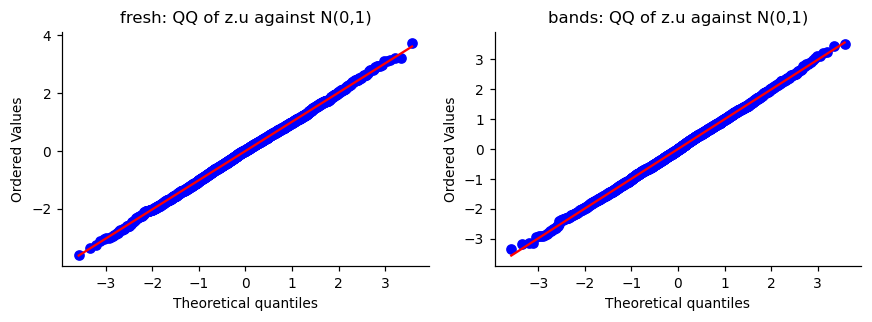

In [2]:
rows = []
for coding in ("fresh", "bands"):
    ds = latent(coding, timescale=4)
    z = ds.sample(20000, 300, np.random.default_rng(1))["obs"].astype(float)[:, 150]
    C = np.cov(z.T)
    rows.append(dict(coding=coding, mean_absmax=np.abs(z.mean(0)).max(), cov_minus_I_absmax=np.abs(C - np.eye(8)).max(),
                     marginal_kurtosis_absmax=np.abs(stats.kurtosis(z, axis=0)).max(),
                     KS_p_min=min(stats.kstest(z[:, j], "norm").pvalue for j in range(8)),
                     mardia=np.mean(np.einsum("ni,ij,nj->n", z, np.linalg.inv(C), z) ** 2)))
display(pd.DataFrame(rows).round(3))

fig, ax = plt.subplots(1, 2, figsize=(8, 3))
for a, coding in zip(ax, ("fresh", "bands")):
    ds = latent(coding, timescale=4)
    z = ds.sample(4000, 300, np.random.default_rng(3))["obs"].astype(float)[:, 150]
    u = ds.sources[0].Q[:, 0]
    stats.probplot(z @ u, dist="norm", plot=a); a.set_title(f"{coding}: QQ of z.u against N(0,1)")
plt.tight_layout(); plt.show()

## 2. ... but the dynamics are not Gaussian

One series of the band latent, projected on the regime direction $u$ and on a random direction, coloured by the true regime, and the distribution of the lag-1 increments against a Gaussian of the same variance.

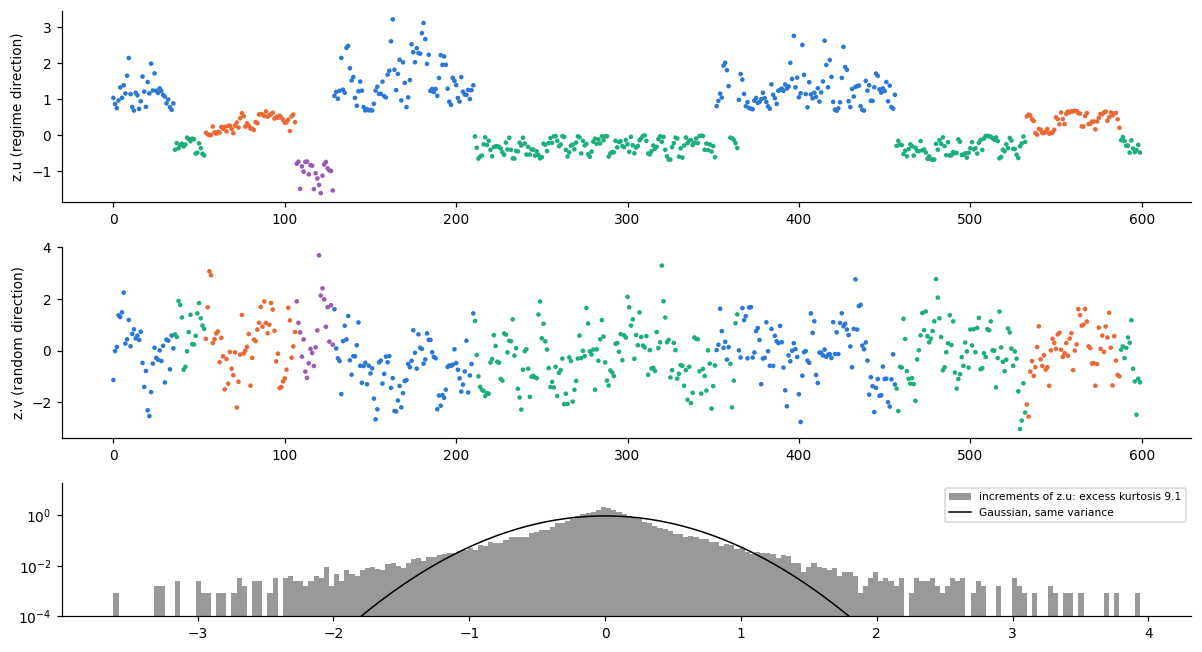

In [3]:
ds = latent("bands", dwell=50, timescale=2)
d = ds.sample(16, 2000, np.random.default_rng(2)); Z, S = d["obs"].astype(float), d["S_s"]
u = ds.sources[0].Q[:, 0]; v = np.random.default_rng(0).standard_normal(8); v -= (v @ u) * u; v /= np.linalg.norm(v)
fig, ax = plt.subplots(3, 1, figsize=(11, 6), gridspec_kw=dict(height_ratios=[2, 2, 1.4]))
for a, w, name in ((ax[0], u, "z.u (regime direction)"), (ax[1], v, "z.v (random direction)")):
    a.scatter(np.arange(600), Z[0, :600] @ w, c=[viz.COLORS[k] for k in S[0, :600]], s=4); a.set_ylabel(name)
inc = np.diff(Z @ u, axis=1).ravel(); g = np.linspace(inc.min(), inc.max(), 200)
ax[2].hist(inc, 200, density=True, color="0.6", log=True, label=f"increments of z.u: excess kurtosis {kurtosis(inc):.1f}")
ax[2].plot(g, stats.norm.pdf(g, 0, inc.std()), "k", lw=1, label="Gaussian, same variance"); ax[2].set_ylim(1e-4)
ax[2].legend(fontsize=7); plt.tight_layout(); plt.show()

## 3. The kurtosis spectrum measures the dwell time

Fresh levels, white within-regime noise, c = 0.8: empirical $\kappa_\tau$ along a random direction (dots) against the closed form (lines) for four dwell times. The dashed lines mark the predicted peak $\tau^* = \ln(2-c)/(-\ln(1-h))$; the predicted height is $3c^2/(4(1-c)) = 2.4$. The grey curve is the phase-surrogate twin (same spectrum, jointly Gaussian): flat at zero.

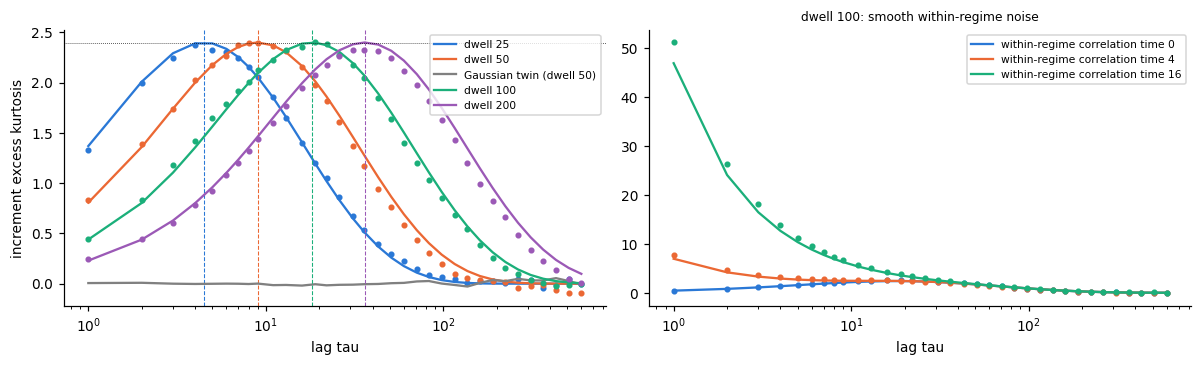

,dwell,tau_star_theory,tau_star_empirical,kappa_max_empirical,dwell_fitted,c_fitted
0,25,4.47,4,2.37,25.53,0.80
1,50,9.02,8,2.40,46.63,0.80
2,100,18.14,19,2.40,94.73,0.80
3,200,36.37,36,2.32,182.48,0.79


In [4]:
c, taus = 0.8, np.unique(np.geomspace(1, 600, 40).astype(int))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
rows = []
for i, dwell in enumerate((25, 50, 100, 200)):
    ds = latent("fresh", dwell=dwell, c=c)
    Z = ds.sample(16, 20000, np.random.default_rng(5))["obs"].astype(float)
    w = np.random.default_rng(i).standard_normal(8); w /= np.linalg.norm(w)
    k_emp = kappa(Z, w, taus)
    ax[0].semilogx(taus, k_emp, "o", ms=3, color=viz.COLORS[i]); ax[0].semilogx(taus, kappa_theory(taus, dwell, c), color=viz.COLORS[i], label=f"dwell {dwell}")
    t_star = np.log(2 - c) / -np.log(1 - 1 / dwell); ax[0].axvline(t_star, color=viz.COLORS[i], ls="--", lw=0.7)
    if dwell == 50:
        ax[0].semilogx(taus, kappa(phase_surrogate(Z, np.random.default_rng(0)), w, taus), color="0.5", label="Gaussian twin (dwell 50)")
    # dwell estimate: fit the closed form (c, dwell free) to the empirical spectrum
    grid_d, grid_c = np.geomspace(5, 1000, 300), np.linspace(0.3, 0.95, 66)
    err = [[np.sum((kappa_theory(taus, dd, cc) - k_emp) ** 2) for dd in grid_d] for cc in grid_c]
    ci, di = np.unravel_index(np.argmin(err), (len(grid_c), len(grid_d)))
    rows.append(dict(dwell=dwell, tau_star_theory=t_star, tau_star_empirical=taus[np.argmax(k_emp)], kappa_max_empirical=k_emp.max(),
                     dwell_fitted=grid_d[di], c_fitted=grid_c[ci]))
ax[0].axhline(3 * c ** 2 / (4 * (1 - c)), color="k", lw=0.5, ls=":")
ax[0].set_xlabel("lag tau"); ax[0].set_ylabel("increment excess kurtosis"); ax[0].legend(fontsize=7)
# within-regime correlation time shifts the short-lag part only
for i, ts in enumerate((0, 4, 16)):
    Z = latent("fresh", dwell=100, c=c, timescale=ts).sample(16, 20000, np.random.default_rng(6))["obs"].astype(float)
    ax[1].semilogx(taus, kappa(Z, np.eye(8)[0], taus), "o", ms=3, color=viz.COLORS[i])
    ax[1].semilogx(taus, kappa_theory(taus, 100, c, ts), color=viz.COLORS[i], label=f"within-regime correlation time {ts}")
ax[1].set_xlabel("lag tau"); ax[1].set_title("dwell 100: smooth within-regime noise", fontsize=8); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()
display(pd.DataFrame(rows).round(2))

Smooth within-regime noise makes short-lag increments small, so jumps dominate them and $\kappa_\tau$ diverges like $1/\tau$ as $\tau \to 0$; the long-lag decay is still set by the dwell time.

For the band latent the jump size depends on which two bands are visited, so there is no closed form, but the same picture holds along $u$, while directions orthogonal to $u$ carry no regime and show $\kappa_\tau \approx 0$.

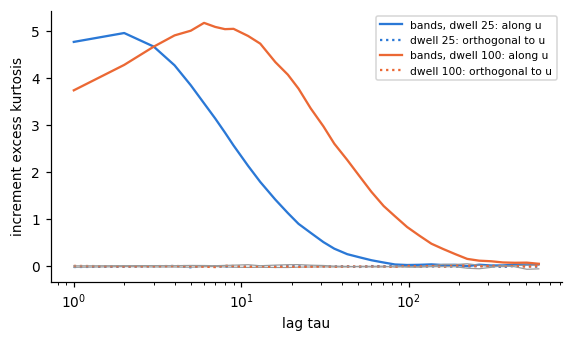

In [5]:
fig, ax = plt.subplots(figsize=(6, 3.2))
for i, dwell in enumerate((25, 100)):
    ds = latent("bands", dwell=dwell); Z = ds.sample(16, 20000, np.random.default_rng(7))["obs"].astype(float); u = ds.sources[0].Q[:, 0]
    ax.semilogx(taus, kappa(Z, u, taus), color=viz.COLORS[i], label=f"bands, dwell {dwell}: along u")
    ax.semilogx(taus, kappa(Z, ds.sources[0].Q[:, 1], taus), color=viz.COLORS[i], ls=":", label=f"dwell {dwell}: orthogonal to u")
    ax.semilogx(taus, kappa(phase_surrogate(Z, np.random.default_rng(0)), u, taus), color="0.6", lw=0.8)
ax.set_xlabel("lag tau"); ax.set_ylabel("increment excess kurtosis"); ax.legend(fontsize=7); plt.show()

## 4. Detectors on the latent

Every registered detector runs on the latent directly (each time step plays the role of one window feature; dwell 50 steps, 16 series × 2000 steps, within-regime correlation time 2). The control is the jointly Gaussian twin: the phase surrogate of the same latent, which has the same spectra and cross-spectra and keeps the labels. Clustering accuracy is meaningless for fresh levels (no label is encoded), so only change-point metrics are shown there. Change-point margin: 5 steps.

In [6]:
rows, dec_keep = [], {}
for coding in ("bands", "fresh"):
    ds = latent(coding, dwell=50, timescale=2)
    d = ds.sample(16, 2000, np.random.default_rng(2)); Z = d["obs"].astype(float); T = Z.shape[1]
    for view, X in (("latent", Z), ("Gaussian twin", phase_surrogate(Z, np.random.default_rng(0)))):
        for n in DETECTORS.available():
            dec = make_detector(n).detect(X, ds.K)
            r = score(dec, np.arange(T), 1, d, ds.K, 5)
            if coding == "fresh":
                r.pop("acc", None)
            rows.append(dict(coding=coding, view=view, detector=n, **{k: r.get(k) for k in ("acc", "cp_ap", "cp_f1")}))
            if coding == "bands" and view == "latent":
                dec_keep[n] = dec
res = pd.DataFrame(rows)
display(res.pivot_table(index="detector", columns=["coding", "view"], values=["acc", "cp_ap"]).round(3))

acc                cp_ap                            
coding                  bands                bands                fresh       
view            Gaussian twin latent Gaussian twin latent Gaussian twin latent
detector                                                                      
arhmm                   0.260  0.621         0.123  0.848         0.062  0.973
bocpd                     NaN    NaN         0.158  0.419         0.167  0.926
contrast                  NaN    NaN         0.148  0.189         0.164  0.969
cpdmd                     NaN    NaN         0.105  0.107         0.097  0.364
dmd_error                 NaN    NaN         0.132  0.161         0.149  0.258
gmm                     0.261  0.478         0.141  0.320         0.122  0.659
hmm                     0.271  0.998         0.155  0.974         0.153  0.702
mmd                       NaN    NaN         0.153  0.203         0.162  0.964
temporal_excess         0.250  0.998         0.000  0.974         0.144  0.691

Reading the table:
- **GMM** sees one Gaussian blob, so its likelihood has no preference for any partition. It still reaches 0.48 on the band latent: the regimes are slabs along $u$, and the detector's label-free choice (the most persistent of several fits) favours fits that cut along the persistent direction. A static model gets partial structure only through that selection step.
- **HMM / temporal excess** use time and recover the regimes; on the twin they drop to chance, so what they use is exactly the non-Gaussian temporal dependence, not anything second-order.
- The change-point detectors respond to the level jumps.

Does temporal excess find the regime direction $u$? Its chosen directions against $u$:

directions found: 2  top excess: [8.98, 8.96, 8.92, 8.82, 0.19, 0.1, 0.1, 0.09]  null threshold: 0.15
|cos(best direction, u)| = 1.000   (in raw latent coordinates; the detector itself works after PCA)


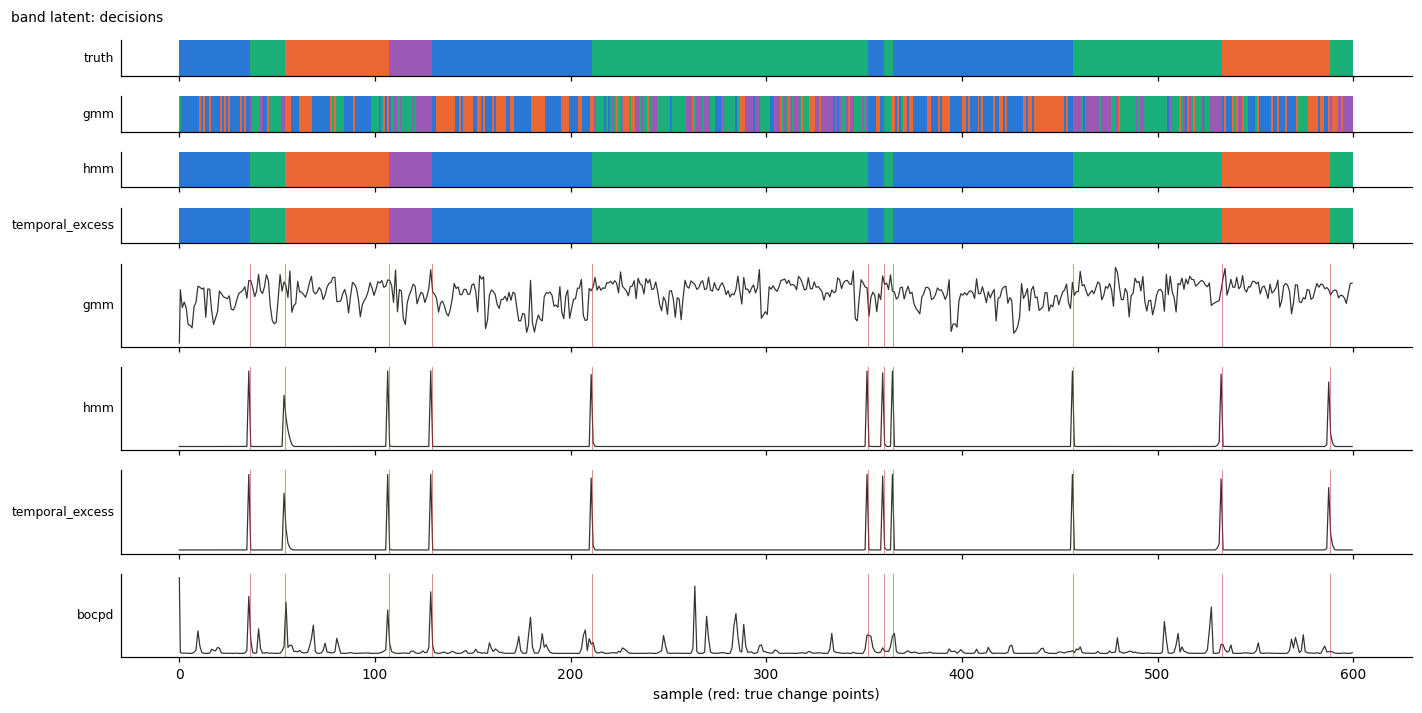

In [7]:
ds = latent("bands", dwell=50, timescale=2); u = ds.sources[0].Q[:, 0]
d = ds.sample(16, 2000, np.random.default_rng(2)); Z = d["obs"].astype(float)
te = make_detector("temporal_excess"); dec = te.detect(Z, ds.K)
print("directions found:", dec["n_dirs"], " top excess:", dec["excess"], " null threshold:", round(dec["null"], 2))
F = contrast_components(Z, te.ms, 0); ex = temporal_excess(Z, F, te.ms); best = F[:, np.argmax(ex)]
print(f"|cos(best direction, u)| = {abs(best @ u):.3f}   (in raw latent coordinates; the detector itself works after PCA)")
viz.plot_decisions(d, {k: dec_keep[k] for k in ("gmm", "hmm", "temporal_excess", "bocpd")}, np.arange(Z.shape[1]), 1, ds.K,
                   title="band latent: decisions", n=600)